In [1]:
import os
import numpy as np
import pickle
import random
import pandas as pd
import copy
import requests

import torch
import torch.nn as nn
import torch.nn.functional as F

from collections import deque
from tqdm import tqdm

import time

# TensorBoard
from pyngrok import ngrok
import subprocess
import port_for
from torch.utils.tensorboard import SummaryWriter

# plotting
import matplotlib.pyplot as plt

In [2]:
os.environ["CUDA_VISIBLE_DEVICES"]="6"

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
seed = 316
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [5]:
def convert(seconds):
    seconds = seconds % (24 * 3600)
    hour = seconds // 3600
    seconds %= 3600
    minutes = seconds // 60
    seconds %= 60

    return "%d:%02d:%02d" % (hour, minutes, seconds)

# Load Data

In [6]:
with open('../data/user_sequences.pkl', 'rb') as f:
    user_sequences = pickle.load(f)
with open('../data/train_sequences.pkl', 'rb') as f:
    train_sequences = pickle.load(f)
with open('../data/test_sequences.pkl', 'rb') as f:
    test_sequences = pickle.load(f)

In [7]:
with open('../data/user2idx.pkl', 'rb') as f:
    user2idx = pickle.load(f)
with open('../data/idx2user.pkl', 'rb') as f:
    idx2user = pickle.load(f)
with open('../data/movie2idx.pkl', 'rb') as f:
    movie2idx = pickle.load(f)
with open('../data/idx2movie.pkl', 'rb') as f:
    idx2movie = pickle.load(f)

In [8]:
with open('../data/user_sequences_idx.pkl', 'rb') as f:
    user_sequences_idx = pickle.load(f)

with open('../data/train_sequences_idx.pkl', 'rb') as f:
    train_sequences_idx = pickle.load(f)

with open('../data/test_sequences_idx.pkl', 'rb') as f:
    test_sequences_idx = pickle.load(f)

In [9]:
user_embeddings = np.load('../data/user_embeddings.npy')
movie_embeddings = np.load('../data/movie_embeddings.npy')

print(f"User embeddings: {user_embeddings.shape} (should match {len(user2idx)} users)")
print(f"Movie embeddings: {movie_embeddings.shape} (should match {len(movie2idx)} movies)")

User embeddings: (6040, 100) (should match 6040 users)
Movie embeddings: (3706, 100) (should match 3706 movies)


In [10]:
pmf_raw_data = pd.read_csv("../data/movielens_1M_pmf_raw_data.csv")
print(f"Loaded {len(pmf_raw_data)} ratings")

Loaded 1000209 ratings


In [11]:
# Load the ratings dictionary
with open('../data/ratings_dict.pkl', 'rb') as f:
    ratings_dict = pickle.load(f)

print(f"Loaded {len(ratings_dict)} entries into ratings_dict")

Loaded 1000209 entries into ratings_dict


# Environment & State Representation

In [12]:
class StateRepresentation(nn.Module):
    """
    This state module models the interaction btwn users & items
    item-item interactions, user-item interactions, AND user's dynamic preference
    
    (from Section 3)
    A state s = the user's positive rating history + user demographic info

    (from Section 4)
    n = the # of most recent movies
    H_a = {i1, i2, ..., in} aka history of n most recent movies

    each movie i_a is in R 1xk

    i_t is recommended item at timestep t

    Update rule:
    If reward is positive, H_t+1 = {i2, i3,..., in, i_t}
    Otherwise, H_t+1 = Ht (Ht is NOT updated)
    so i_t can be addted to H to become a future i_a

    Input:
    The n most recent Embedded items
    the user embedding

    Deep Reinforcement Recommendation-Average Pooling
    DRR-ave: Represents state by using Avg. pooling 
    over recent movie embeddings to model user-item interactions
    Removes position effects in the item history

    Output: state vector with a size of 3*k
    
    s = [u, u ⊗ g(i_a), g(i_a)]
    where g(i_a) = weighted average of item embeddings

    embed_dim = k = 100 (fixed)
    """
    def __init__(self, user_embeddings, item_embeddings, n_history=5):
        super().__init__()
        self.n_history = n_history
        self.embed_dim = item_embeddings.shape[1]

        # the size of the concatenated state [u, u⊗g, g]
        self.output_dim = 3 * self.embed_dim
        
        # Use & Freeze Pretrained embeddings from PMF
        self.user_embeddings = nn.Embedding.from_pretrained(torch.FloatTensor(user_embeddings), freeze=True)
        self.item_embeddings = nn.Embedding.from_pretrained(torch.FloatTensor(item_embeddings), freeze=True)
        
        # Learnable importance weights for items (position matters in sequence)
        # Init to 1, update/learn better values later
        self.item_weights = nn.Parameter(torch.ones(n_history))
    
    def forward(self, user_ids, item_ids):
        """
        This function is never called explicitly,
        BUT it IS called under the hood bc every nn.Module object has a built-in
        function named __call__, so whenever you include () after the state_module object
        Python calls __call__(), which calls forward()
        SO: Whenever you retrieve an instnace of StateRepresentation by doing 
        trainer.state_module(user_tensor, history_tensor), forward() is called!
        
        Args:
            user_ids: (batch_size,) tensor of user indices
            item_ids: (batch_size, n_history) tensor of item indices
        Returns:
            state: (batch_size, output_dim) state representation
        """
        batch_size = user_ids.shape[0]
        
        # Get user embeddings
        u = self.user_embeddings(user_ids)  # (batch_size, embed_dim)
        
        # Get item embeddings for history
        H = self.item_embeddings(item_ids)  # (batch_size, n_history, embed_dim)
        
        # Apply importance weights (softmax to make them sum to 1)
        weights = torch.softmax(self.item_weights, dim=0)  # (n_history,)
        weighted_H = H * weights.view(1, -1, 1)  # (batch_size, n_history, embed_dim)
        
        # Weighted average pooling g(i_a)
        g = weighted_H.sum(dim=1)  # (batch_size, embed_dim)
        
        # Compute user-item interaction u ⊗ g (element-wise product)
        u_g_interaction = u * g  # (batch_size, embed_dim)
        
        # Concatenate: [u, u⊗g, g]
        state = torch.cat([u, u_g_interaction, g], dim=1)  # (batch_size, 3*embed_dim)

        # HYPOTHETICALLY Adding demographics: [u, u⊗g, g, d]
        # state = torch.cat([u, u_g_interaction, g, demographic_vector], dim=1)

        return state
    
    def get_output_dim(self):
        return self.output_dim

# Actor and Critic Classes

In [13]:
class Actor(nn.Module):
    """
    Randomly initialize the Actor πθ
    Thus assuming standard implementation.
    
    maps: state -> action
    From paper: "By two ReLU layers and one Tanh layer, the state representation s 
    is transformed into an action a = π_θ(s)"
    """
    def __init__(self, state_dim, action_dim=100, hidden_dim=256):
        super().__init__()
        self.fc1 = nn.Linear(state_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, action_dim)
        
        # Initialize weights
        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.xavier_uniform_(self.fc2.weight)
        nn.init.xavier_uniform_(self.fc3.weight)
        
    def forward(self, state):
        x = F.relu(self.fc1(state))
        x = F.relu(self.fc2(x))
        # Tanh maps action to [-1, 1]
        action = torch.tanh(self.fc3(x))
        return action

In [14]:
class Critic(nn.Module):
    """
    Randomly initialize Critic Q_w
    w is "omega", the Critic parameters
    
    Maps: (state, action) -> Q-value
    Deep Q-Network that estimates the value of taking an action in a given state
    """
    def __init__(self, state_dim, action_dim=100, hidden_dim=256):
        super().__init__()
        # Input: Concatenation of state & action
        self.fc1 = nn.Linear(state_dim + action_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, 1)  # Output scalar Q-value
        
        # Initialize weights
        nn.init.xavier_uniform_(self.fc1.weight)
        nn.init.xavier_uniform_(self.fc2.weight)
        nn.init.xavier_uniform_(self.fc3.weight)
        
    def forward(self, state, action):
        x = torch.cat([state, action], dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        q_value = self.fc3(x)
        return q_value

# Implementation of Equation 2

In [15]:
# Actor takes in state, outputs an action.
# Each action is a continuous 1xk row vector used to score items. IT is NOT a movie.
# The top ranked movies are recommended to the user (according to epsilon greedy)
# item_embeddings: all movies in MovieLens 1M
# epsilon set to 0.1 is standard practice
# num items: all unique movies in MovieLens 1M
# 3533 movies because
# 1. I only kept userIDs who rated movies 4 or 5
# 2. I then only kept ALL movies THOSE users rated
# embed_dim = k = 100
class ItemRanker:
    """
    Ranks items based on action vector and item embeddings
    Implements Eq. 2: score = item_embedding · action^T
    """
    def __init__(self, item_embeddings, epsilon=0.1):
        """
        Args:
            item_embeddings: numpy array of shape (num_items, embed_dim)
            epsilon: exploration rate for ε-greedy
        """
        self.item_embeddings = torch.FloatTensor(item_embeddings)
        self.epsilon = epsilon
        self.num_items = item_embeddings.shape[0]
        self.embed_dim = item_embeddings.shape[1]
        
    def get_all_scores(self, action):
        """
        Compute scores for all items
        Args:
            action: (batch_size, embed_dim) action vector
        Returns:
            scores: (batch_size, num_items) scores for all items
        """
        # Dot product: (batch_size, embed_dim) @ (embed_dim, num_items)
        scores = action @ self.item_embeddings.T  # (batch_size, num_items)
        return scores
    
    def select_item(self, action, candidate_items=None, exclude_items=None):
        """
        Select an item using ε-greedy
        Args:
            action: (embed_dim,) action vector for a single user
            candidate_items: list of candidate item indices (if None, use all items)
            exclude_items: set of items to exclude (already recommended)
        Returns:
            selected_item: index of selected item
        """
        action = action.squeeze()  # Ensure 1D
        
        # Get candidate items
        if candidate_items is None:
            candidate_items = list(range(self.num_items))
        
        # Filter out excluded items
        if exclude_items:
            filtered_items = []
            for i in candidate_items:
                if i not in exclude_items:
                    filtered_items.append(i)            
            candidate_items = filtered_items
        
        if not candidate_items:
            return None
        
        # ε-greedy exploration
        if np.random.random() < self.epsilon:
            # If it meets the threshold, Explore: random item
            return np.random.choice(candidate_items)
        else:
            # If it doesn't meet the threshold, Exploit: best item by score
            # candidate_embeddings = self.item_embeddings[candidate_items]  # (n_candidates, embed_dim)
            candidate_embeddings = self.item_embeddings[candidate_items].to(action.device)  # <-- THIS IS THE FIX
            scores = action @ candidate_embeddings.T  # (n_candidates,)
            best_idx = torch.argmax(scores).item()
            return candidate_items[best_idx]

# Replay Buffer

In [16]:
# The paper doesn't specify how to make the Prioritized Replay Buffer
# but they cite the original PER paper: Schaul et al., 2016
# So assume: standard PER implementation
class PrioritizedReplayBuffer:
    """
    Prioritized Experience Replay buffer
    Stores transitions (state, action, reward, next_state, done)
    """
    def __init__(self, capacity, alpha=0.6, beta=0.4, beta_increment=0.001):
        self.capacity = capacity
        self.alpha = alpha  # prioritization exponent
        self.beta = beta  # importance sampling exponent
        self.beta_increment = beta_increment
        self.buffer = []
        self.priorities = []
        self.position = 0
        
    def push(self, state, action, reward, next_state, done):
        """Add a transition to the buffer"""
        # Max priority for new transitions
        max_priority = max(self.priorities) if self.priorities else 1.0
        
        if len(self.buffer) < self.capacity:
            self.buffer.append((state, action, reward, next_state, done))
            self.priorities.append(max_priority)
        else:
            self.buffer[self.position] = (state, action, reward, next_state, done)
            self.priorities[self.position] = max_priority
        
        self.position = (self.position + 1) % self.capacity
    
    def sample(self, batch_size):
        """Sample a batch of transitions with prioritization"""
        if len(self.buffer) < batch_size:
            return None
        
        # Calculate sampling probabilities
        priorities = np.array(self.priorities[:len(self.buffer)])
        probs = priorities ** self.alpha
        probs /= probs.sum()
        
        # Sample indices
        indices = np.random.choice(len(self.buffer), batch_size, p=probs)
        
        # Calculate importance sampling weights
        total = len(self.buffer)
        weights = (total * probs[indices]) ** (-self.beta)
        weights /= weights.max()
        weights = torch.FloatTensor(weights).to(device)
        
        # Update beta
        self.beta = min(1.0, self.beta + self.beta_increment)
        
        # Get transitions
        batch = [self.buffer[idx] for idx in indices]
        
        # Unpack batch
        states, actions, rewards, next_states, dones = zip(*batch)
        
        # Convert to tensors and move to device
        # states = torch.FloatTensor(np.array(states)).to(device)
        # actions = torch.FloatTensor(np.array(actions)).to(device)
        # next_states = torch.FloatTensor(np.array(next_states)).to(device)
        states = torch.stack(states).to(device)
        actions = torch.stack(actions).to(device)
        next_states = torch.stack(next_states).to(device)

        rewards = torch.FloatTensor(np.array(rewards)).unsqueeze(1).to(device)
        dones = torch.FloatTensor(np.array(dones)).unsqueeze(1).to(device)
        
        return states, actions, rewards, next_states, dones, weights, indices
    
    def update_priorities(self, indices, td_errors):
        """Update priorities based on TD errors"""
        for idx, td_error in zip(indices, td_errors):
            self.priorities[idx] = abs(td_error) + 1e-6
    
    def __len__(self):
        return len(self.buffer)

# DDPG Trainer

In [18]:
class DDPGTrainer:
    """
    DDPG Trainer for DRR framework
    Implements Algorithm 1 from the paper
    """
    def __init__(self, actor, critic, state_module, item_ranker, replay_buffer,
                 actor_lr=1e-4, critic_lr=1e-3, gamma=0.9, tau=0.001, batch_size=32):
        self.actor = actor
        self.critic = critic
        self.state_module = state_module
        self.item_ranker = item_ranker
        self.replay_buffer = replay_buffer
        
        # Hyperparameters
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        
        # Target networks
        self.actor_target = copy.deepcopy(self.actor).to(device)
        self.critic_target = copy.deepcopy(self.critic).to(device)
        # Copy weights
        self.actor_target.load_state_dict(actor.state_dict())
        self.critic_target.load_state_dict(critic.state_dict())

        # Optimizers
        self.actor_optimizer = torch.optim.Adam(actor.parameters(), lr=actor_lr)
        self.critic_optimizer = torch.optim.Adam(critic.parameters(), lr=critic_lr)
        
        # Training step Counter for tensorboard
        self.training_step = 0
        
    def get_action(self, state, epsilon=0.1):
        """Get action from actor with exploration"""
        with torch.no_grad():
            # Call the Actor .forward() function
            action = self.actor(state)
            
            # Add noise for exploration (ε-greedy is handled in item selection)
            if np.random.random() < epsilon:
                # Add small random noise
                noise = torch.randn_like(action) * 0.1
                action = action + noise
                # Squash it back down to [-1, 1] AFTER adding noise
                action = torch.tanh(action)
            
        return action
    
    def update(self):
        """Update networks using sampled batch"""
        if len(self.replay_buffer) < self.batch_size:
            return None
        
        # Sample memories from replay buffer: get rand batch of 32 past interactions
        states, actions, rewards, next_states, dones, weights, indices = self.replay_buffer.sample(self.batch_size)
        
        # Update Critic
        with torch.no_grad():
            # Calculate the TD Target
            next_actions = self.actor_target(next_states)
            # y_i = r_i + gamma * Q_ω′(s_{i+1}, πθ′(si+1))
            target_q = rewards + self.gamma * self.critic_target(next_states, next_actions) * (1 - dones)
        
        current_q = self.critic(states, actions)
        td_errors = (current_q - target_q).detach().squeeze().cpu().numpy()
        
        # Weighted MSE loss
        critic_loss = (weights * (current_q - target_q).squeeze() ** 2).mean()
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.critic.parameters(), 1.0)
        self.critic_optimizer.step()
        
        # Update Actor
        actor_loss = -self.critic(states, self.actor(states)).mean()
        self.training_step += 1
        # X-axis = training_step number
        # Y-axis = Loss, or MeanQ, or MeanTargetQ, or MeanReward, etc.
        writer.add_scalar("Loss/Critic", critic_loss.item(), self.training_step)
        writer.add_scalar("Loss/Actor", actor_loss.item(), self.training_step)
        writer.add_scalar("Stats/Mean_Q", current_q.mean().item(), self.training_step)
        writer.add_scalar("Stats/Mean_Target_Q", target_q.mean().item(), self.training_step)
        writer.add_scalar("Stats/Mean_Reward", rewards.mean().item(), self.training_step)

        writer.add_scalar("Stats/Max_Q", current_q.max().item(), self.training_step)
        writer.add_scalar("Stats/Min_Q", current_q.min().item(), self.training_step)
        
        writer.add_scalar("Stats/Max_Target_Q", target_q.max().item(), self.training_step)
        writer.add_scalar("Stats/Min_Target_Q", target_q.min().item(), self.training_step)
        
        writer.add_scalar("Stats/Max_Reward", rewards.max().item(), self.training_step)
        writer.add_scalar("Stats/Min_Reward", rewards.min().item(), self.training_step)
        
        writer.add_scalar("Stats/Max_Weight", weights.max().item(), self.training_step)
        writer.add_scalar("Stats/Mean_Weight", weights.mean().item(), self.training_step)

        if self.training_step % 10000 == 0:
            print(f"Mean_Q: {current_q.mean().item():.4f} | "
                  # f"Max_Q: {current_q.max().item():.4f} | "
                  f"Mean_Target_Q: {target_q.mean().item():.4f} | "
                  # f"Max_Weight: {weights.max().item():.4f}"
                )
                
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.actor.parameters(), 1.0)
        self.actor_optimizer.step()
        
        # Update priorities
        self.replay_buffer.update_priorities(indices, td_errors)
        # Soft update target networks
        self.soft_update()
        
        return critic_loss.item(), actor_loss.item()
    
    def soft_update(self):
        """Soft update target networks: θ_target = τ*θ + (1-τ)*θ_target"""
        for target_param, param in zip(self.actor_target.parameters(), self.actor.parameters()):
            target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)
        
        for target_param, param in zip(self.critic_target.parameters(), self.critic.parameters()):
            target_param.data.copy_(self.tau * param.data + (1 - self.tau) * target_param.data)

# Algorithm 1

In [19]:
def train_drr(trainer, 
              train_sequences_idx, user2idx, movie2idx, idx2movie, 
              ratings_dict,
              num_episodes=1, T_max=10, epsilon=0.1, patience=5, min_delta=0.001):
    """
    Full training loop for DRR (Algorithm 1)
    
    Args:
    trainer: DDPGTrainer instance
    train_sequences_idx: dict of {user indices: [movie indices]} for training
    user2idx: mapping from user_id to index
    movie2idx: mapping from movie_id to index
    idx2movie: mapping from index to movie_id
    num_episodes: number of episodes (M in Algorithm 1)
    T_max: max timesteps per episode (tuned per dataset)
    epsilon: exploration rate
    """
    all_users = list(train_sequences_idx.keys())
    
    # Tracking metrics
    episode_rewards = []
    avg_episode_rewards = []
    critic_losses = []
    actor_losses = []
    global_step = 0
    best_model_saved = False

    # For early stopping
    best_avg_reward = -float('inf')
    patience_counter = 0
    best_episode = 0
    
    m = range(num_episodes)
    for episode in tqdm(m, desc="Training episodes"):
        # Shuffle users each episode
        np.random.shuffle(all_users)
        total_episode_reward = 0
        users_processed = 0

        # Main training loop (Algorithm 1 line 4)
        # for user_idx in all_users:   
        for user_idx in tqdm(all_users, desc=f"Episode {episode+1} users", leave=False):
            # Get user's sequence
            sequence = train_sequences_idx[user_idx]
            # print(f"Length:{len(sequence)}")
            # print(f"N: {trainer.state_module.n_history + 1}")
            if len(sequence) < trainer.state_module.n_history + 1:
                # Not enough interactions
                # print("Not enough interactions")
                # print(f"Length:{len(sequence)}")
                # print(f"N: {trainer.state_module.n_history + 1}")
                continue  
                
            # Initialize state (first n_history items)
            n = trainer.state_module.n_history
            pos_history = sequence[:n]
            remaining_items = sequence[n:]
            recommended_in_session = set()
            user_total_reward = 0
            
            # Run episode (Algorithm 1 lines 6-12)
            for t in range(min(T_max, len(remaining_items))):
                # Current state (user_idx + pos_history)
                user_tensor = torch.LongTensor([user_idx]).to(device)
                history_tensor = torch.LongTensor([pos_history]).to(device)
                
                # Observe current state
                with torch.no_grad():
                    state = trainer.state_module(user_tensor, history_tensor)
                
                # Get action from actor (with exploration)
                action = trainer.get_action(state, epsilon=epsilon)
                
                # Select item to recommend (Algorithm 1 line 9)
                candidate_items = list(set(remaining_items) - set(pos_history) - recommended_in_session)
                if not candidate_items:
                    break
                    
                # ε-greedy item selection
                selected_item = trainer.item_ranker.select_item(
                    action,
                    candidate_items=candidate_items,
                    exclude_items=set(pos_history)
                )
                recommended_in_session.add(selected_item)
                
                # REWARD:
                rating = ratings_dict[(user_idx, selected_item)]
                reward = (rating - 3) / 2.0
                # "Positive ratings" == 4 or 5 stars
                
                # Update history (Algorithm 1 line 11)
                if reward > 0:
                    new_history = pos_history[1:] + [selected_item]
                else:
                    new_history = pos_history
        
                # Get next state
                with torch.no_grad():
                    next_state = trainer.state_module(user_tensor, torch.LongTensor([new_history]).to(device))
        
                # Check if episode done
                done = (t == min(T_max, len(remaining_items)) - 1)
                
                # Store transition (Algorithm 1 line 12)
                trainer.replay_buffer.push(
                    state.squeeze(),
                    action.squeeze(),  
                    reward,                 
                    next_state.squeeze(),  
                    done                    
                )
                
                # sample minibatch of N transitions (Algorithm 1 lines 13-17)
                if len(trainer.replay_buffer) >= trainer.batch_size:
                    # trainer.update() does:
                    # Sample minibatch of N transions
                    # Update TD Target, y_i 
                    # Update Critic network
                    # Updates Actor network
                    # Updates the target networks
                    critic_loss, actor_loss = trainer.update()
        
                    # Record losses for curves
                    if critic_loss and actor_loss:
                        critic_losses.append(critic_loss)
                        actor_losses.append(actor_loss)
        
                # SUM up the per-step reward over all users and all timesteps in one episode
                user_total_reward += reward
                # Update for next timestep
                pos_history = new_history

            writer.add_scalar("Train/User_Reward", user_total_reward, global_step)  
            global_step += 1

            total_episode_reward += user_total_reward
            users_processed += 1
            # print(f"User {users_processed} done")

            
        avg_episode_reward = total_episode_reward / users_processed if users_processed > 0 else 0
        episode_rewards.append(total_episode_reward)
        avg_episode_rewards.append(avg_episode_reward)
        
        writer.add_scalar("Episode/Total_Reward", total_episode_reward, episode)
        writer.add_scalar("Episode/Avg_Reward_Per_User", avg_episode_reward, episode)

        # Print progress every episode
        print(f"\nEpisode {episode+1}/{num_episodes}")
        print(f"  Total reward: {total_episode_reward:.2f}")
        print(f"  Avg reward per user: {avg_episode_reward:.4f}")
        if critic_losses:
            print(f"  Avg Critic loss: {np.mean(critic_losses[-100:]):.4f}")
            print(f"  Avg Actor loss: {np.mean(actor_losses[-100:]):.4f}")

        # ===== EARLY STOPPING CHECK =====
        if avg_episode_reward > best_avg_reward + min_delta:
            # Improvement detected
            best_avg_reward = avg_episode_reward
            patience_counter = 0
            best_episode = episode
            best_model_saved = True
            
            # Save best model
            torch.save(trainer.actor.state_dict(), '../models/best_actor.pth')
            torch.save(trainer.critic.state_dict(), '../models/best_critic.pth')
            print(f"New best model! Saved (avg reward: {best_avg_reward:.4f})")
        else:
            # No improvement
            patience_counter += 1
            print(f"No improvement for {patience_counter} episodes (best: {best_avg_reward:.4f})")
            
            if patience_counter >= patience:
                print(f"\n=== EARLY STOPPING at episode {episode+1} ===")
                print(f"Best avg reward: {best_avg_reward:.4f} at episode {best_episode+1}")
                break

    # Load best model before returning
    if best_model_saved:
        trainer.actor.load_state_dict(torch.load('../models/best_actor.pth'))
        trainer.critic.load_state_dict(torch.load('../models/best_critic.pth'))
        print(f"\nLoaded best model from episode {best_episode+1}")
    else:
        print("No best model was saved.")
    return episode_rewards, avg_episode_rewards, critic_losses, actor_losses, trainer

# Train Agent using RL

In [20]:
# Parameter configuration dictionary
# Config 1
# hps = {
#     'n': 5,
#     'epsilon': 0.1,
#     'buffer_capacity': 100000,
    
#     'actor_lr': 0.00001,
#     'critic_lr': 0.00005,
#     'gamma': 0.9,
#     'tau': 0.001,
#     'batch_size': 32,
#     'num_episodes': 1,
#     'T_max': 10
# }


# Config 2
# hps = {
#     'n': 5,
#     'epsilon': 0.1,
#     'buffer_capacity': 100_000,
    
#     'actor_lr': 0.00001,
#     'critic_lr': 0.00005,
#     'gamma': 0.9,
#     'tau': 0.0005,
#     'batch_size': 64,
#     'num_episodes': 1,
#     'T_max': 10,
#     'patience':5, 
#     'min_delta':0.001
# }

hps = {
    'n': 5,
    'epsilon': 0.1,
    'buffer_capacity': 100_000,
    
    'actor_lr': 0.00001,
    'critic_lr': 0.00005,
    'gamma': 0.9,
    'tau': 0.0005,
    'batch_size': 64,
    'num_episodes': 10,
    'T_max': 10,
    'patience':5, 
    'min_delta':0.001
}

In [21]:
# Create state representation
state_module = StateRepresentation(user_embeddings, movie_embeddings, n_history=hps["n"])

# Create actor and critic
state_dim = state_module.get_output_dim()
actor = Actor(state_dim)
critic = Critic(state_dim)

print(f"\n# of movies: {movie_embeddings.shape[0]}")
print(f"# of Embed Dims, K: {movie_embeddings.shape[1]}")
print(f"State dimensionality, 3 * K: {state_dim}") # Should be 300
print(f"\nActor: {actor}")
print(f"\nCritic: {critic}")

# Create item ranker
item_ranker = ItemRanker(movie_embeddings, epsilon=hps["epsilon"])

# Create replay buffer
replay_buffer = PrioritizedReplayBuffer(hps["buffer_capacity"])

# Move to GPU
actor = Actor(state_dim).to(device)
critic = Critic(state_dim).to(device)
state_module = state_module.to(device)


# of movies: 3706
# of Embed Dims, K: 100
State dimensionality, 3 * K: 300

Actor: Actor(
  (fc1): Linear(in_features=300, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=100, bias=True)
)

Critic: Critic(
  (fc1): Linear(in_features=400, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=1, bias=True)
)


In [22]:
# Create folder to store TensorBoard tracking
version_number = 2
writer = SummaryWriter(log_dir=f"runs/drr_ddpg_experiment_{version_number}")

In [23]:
port = port_for.get_port(None)
print(f"Starting TensorBoard on port: {port}")

# Kill existing tensorboard
subprocess.run(["pkill", "-f", "tensorboard"])

# Start tensorboard
subprocess.Popen(["tensorboard", "--logdir", "./runs/", "--port", f"{port}", "--host", "0.0.0.0"])

# Wait a moment
time.sleep(3)

# Test connection
try:
    r = requests.get(f"http://localhost:{port}")
    print(f"ssh -L {port}:localhost:{port} -N law3082@narnia.gccis.rit.edu")
    print(f"TensorBoard is running! Status: {r.status_code}")
    print(f"http://localhost:{port}")
except:
    print("TensorBoard failed to start")

Starting TensorBoard on port: 11279


TensorFlow installation not found - running with reduced feature set.

NOTE: Using experimental fast data loading logic. To disable, pass
    "--load_fast=false" and report issues on GitHub. More details:
    https://github.com/tensorflow/tensorboard/issues/4784

TensorBoard 2.20.0 at http://0.0.0.0:11279/ (Press CTRL+C to quit)


ssh -L 11279:localhost:11279 -N law3082@narnia.gccis.rit.edu
TensorBoard is running! Status: 200
http://localhost:11279


In [24]:
# Create trainer
trainer = DDPGTrainer(
    actor=actor,
    critic=critic,
    state_module=state_module,
    item_ranker=item_ranker,
    replay_buffer=replay_buffer,
    actor_lr=hps['actor_lr'],
    critic_lr=hps['critic_lr'],
    gamma=hps['gamma'],
    tau=hps['tau'],
    batch_size=hps['batch_size']
)

# Train
print("Training started")
start_time = time.time()

total_episode_rewards, avg_episode_rewards, critic_losses, actor_losses, trainer = train_drr(
    trainer=trainer,
    train_sequences_idx=train_sequences_idx,
    user2idx=user2idx,
    movie2idx=movie2idx,
    idx2movie=idx2movie,
    ratings_dict=ratings_dict,
    num_episodes=hps['num_episodes'],
    T_max=hps['T_max'],
    epsilon=hps['epsilon'],
    patience=hps['patience'],
    min_delta=hps['min_delta']
)

end_time = time.time()
print("Training done")
writer.close()

# Save only the state dictionaries
torch.save(actor.state_dict(), f'../models/drr_actor_weights_{version_number}.pth')
torch.save(critic.state_dict(), f'../models/drr_critic_weights_{version_number}.pth')
print("\nTraining complete! Models saved.")

Training started


Episode 1 users:  17%|██████████████▏                                                                      | 1006/6040 [26:41<1:49:28,  1.30s/it]

Mean_Q: 3.2841 | Mean_Target_Q: 2.7804 | 



Episode 1 users:  33%|████████████████████████████▏                                                        | 2006/6040 [52:19<1:28:42,  1.32s/it]

Mean_Q: 6.1344 | Mean_Target_Q: 5.7328 | 


...

Mean_Q: 5.8659 | Mean_Target_Q: 5.0264 | 



Episode 10 users:  93%|██████████████████████████████████████████████████████████████████████████████▌     | 5646/6040 [2:41:41<10:05,  1.54s/it]

Mean_Q: 5.5110 | Mean_Target_Q: 5.1271 | 



Training episodes: 100%|███████████████████████████████████████████████████████████████████████████████████| 10/10 [28:23:42<00:00, 10222.20s/it]
/tmp/ipykernel_2877336/3174246734.py:181: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on 


Episode 10/10
  Total reward: 22043.00
  Avg reward per user: 3.6495
  Avg Critic loss: 0.4343
  Avg Actor loss: -7.2687
New best model! Saved (avg reward: 3.6495)

Loaded best model from episode 10
Training done

Training complete! Models saved.


In [25]:
# Calculate run time
training_duration = end_time - start_time
train_time_in_minutes_and_seconds = convert(training_duration)
print(f"Time taken: {train_time_in_minutes_and_seconds}")

Time taken: 4:23:42


In [26]:
def plot_training_curves(rewards, critic_losses, actor_losses):
    # Plot Episode Rewards
    plt.figure()
    plt.plot(rewards)
    plt.xlabel("Episode")
    plt.ylabel("Total Reward")
    plt.title("Episode Rewards")
    plt.savefig('../figures/baseline_episode_rewards.png', bbox_inches='tight', dpi=300)
    plt.show()

    # Plot Critic Loss
    plt.figure()
    plt.plot(critic_losses)
    plt.xlabel("Training Step")
    plt.ylabel("Critic Loss")
    plt.title("Critic Loss")
    plt.savefig('../figures/baseline_critic_loss.png', bbox_inches='tight', dpi=300)
    plt.show()

    # Plot Actor Loss
    plt.figure()
    plt.plot(actor_losses)
    plt.xlabel("Training Step")
    plt.ylabel("Actor Loss")
    plt.title("Actor Loss")
    plt.savefig('../figures/baseline_actor_loss.png', bbox_inches='tight', dpi=300)
    plt.show()

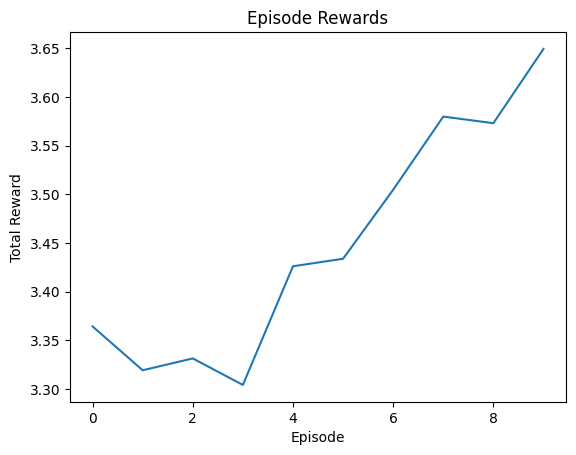

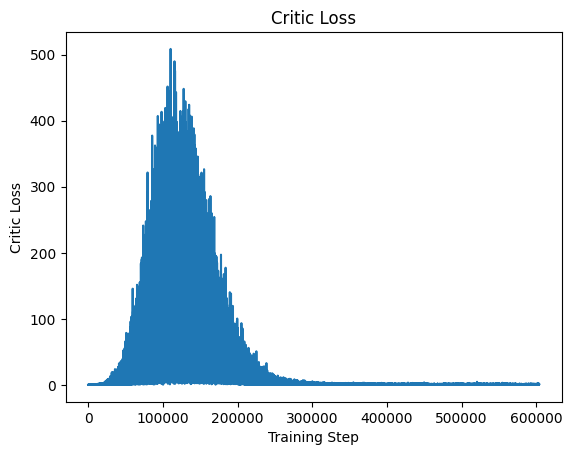

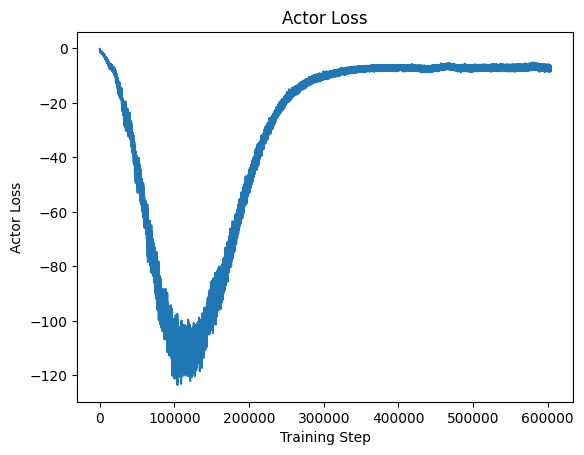

In [27]:
plot_training_curves(avg_episode_rewards, critic_losses, actor_losses)